# get the lowest R2

In [ ]:
#  find the max R2 snapshot:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


def load_r2_list(json_path: str | Path, key: str | None = None) -> list[float]:
    """
    Load R2 values from a JSON file.

    Supports:
      1) A JSON list:            [0.51, 0.53, 0.49, ...]
      2) A JSON dict with key:   {"r2": [0.51, 0.53, ...]}  (set key="r2")
      3) A JSON dict of values:  {"run1": 0.51, "run2": 0.53, ...} (key=None)
    """
    json_path = Path(json_path)
    with json_path.open("r") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        r2 = obj
    elif isinstance(obj, dict):
        if key is not None:
            if key not in obj:
                raise KeyError(f"Key '{key}' not found. Available keys: {list(obj.keys())[:20]}")
            r2 = obj[key]
        else:
            # dict of scalar values -> take values in insertion order
            r2 = list(obj.values())
    else:
        raise TypeError(f"Unsupported JSON type: {type(obj)}")

    # Cast to float and validate
    out = []
    for i, v in enumerate(r2):
        try:
            out.append(float(v))
        except Exception as e:
            raise ValueError(f"Could not convert r2[{i}]={v!r} to float") from e

    return out


def plot_r2(r2: list[float], x: list[float] | None = None, title: str = "R² over index"):
    """
    Plot R2 vs index (default) or vs provided x.
    """
    if x is None:
        x = list(range(len(r2)))
        xlabel = "Index"
    else:
        if len(x) != len(r2):
            raise ValueError(f"x and r2 must have same length: {len(x)} vs {len(r2)}")
        xlabel = "x"

    plt.figure()
    plt.plot(x, r2, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("R²")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_19/test_stats.json", key="image_r2_list")

print(len(r2))
print("index:", np.argmin(r2), "max value:", np.min(r2))

# we find that cfg_19 and cfg_17 has the max snapshot r2, 0.75 and 0.73


# How R2 change with time in test data

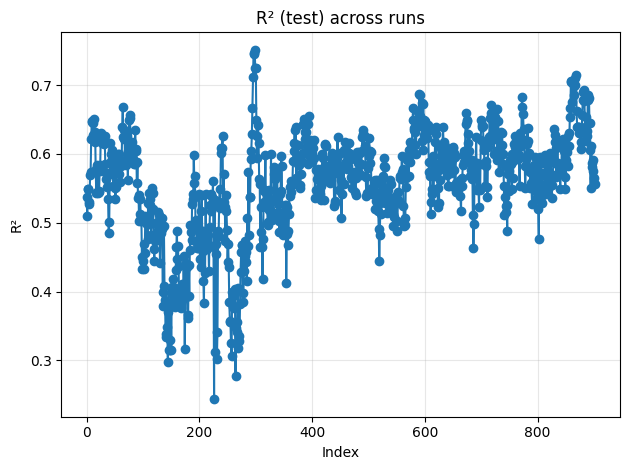

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt


def load_r2_list(json_path: str | Path, key: str | None = None) -> list[float]:
    """
    Load R2 values from a JSON file.

    Supports:
      1) A JSON list:            [0.51, 0.53, 0.49, ...]
      2) A JSON dict with key:   {"r2": [0.51, 0.53, ...]}  (set key="r2")
      3) A JSON dict of values:  {"run1": 0.51, "run2": 0.53, ...} (key=None)
    """
    json_path = Path(json_path)
    with json_path.open("r") as f:
        obj = json.load(f)

    if isinstance(obj, list):
        r2 = obj
    elif isinstance(obj, dict):
        if key is not None:
            if key not in obj:
                raise KeyError(f"Key '{key}' not found. Available keys: {list(obj.keys())[:20]}")
            r2 = obj[key]
        else:
            # dict of scalar values -> take values in insertion order
            r2 = list(obj.values())
    else:
        raise TypeError(f"Unsupported JSON type: {type(obj)}")

    # Cast to float and validate
    out = []
    for i, v in enumerate(r2):
        try:
            out.append(float(v))
        except Exception as e:
            raise ValueError(f"Could not convert r2[{i}]={v!r} to float") from e

    return out


def plot_r2(r2: list[float], x: list[float] | None = None, title: str = "R² over index"):
    """
    Plot R2 vs index (default) or vs provided x.
    """
    if x is None:
        x = list(range(len(r2)))
        xlabel = "Index"
    else:
        if len(x) != len(r2):
            raise ValueError(f"x and r2 must have same length: {len(x)} vs {len(r2)}")
        xlabel = "x"

    plt.figure()
    plt.plot(x, r2, marker="o")
    plt.xlabel(xlabel)
    plt.ylabel("R²")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_19/test_stats.json", key="image_r2_list")
plot_r2(r2, title="R² (test) across runs")


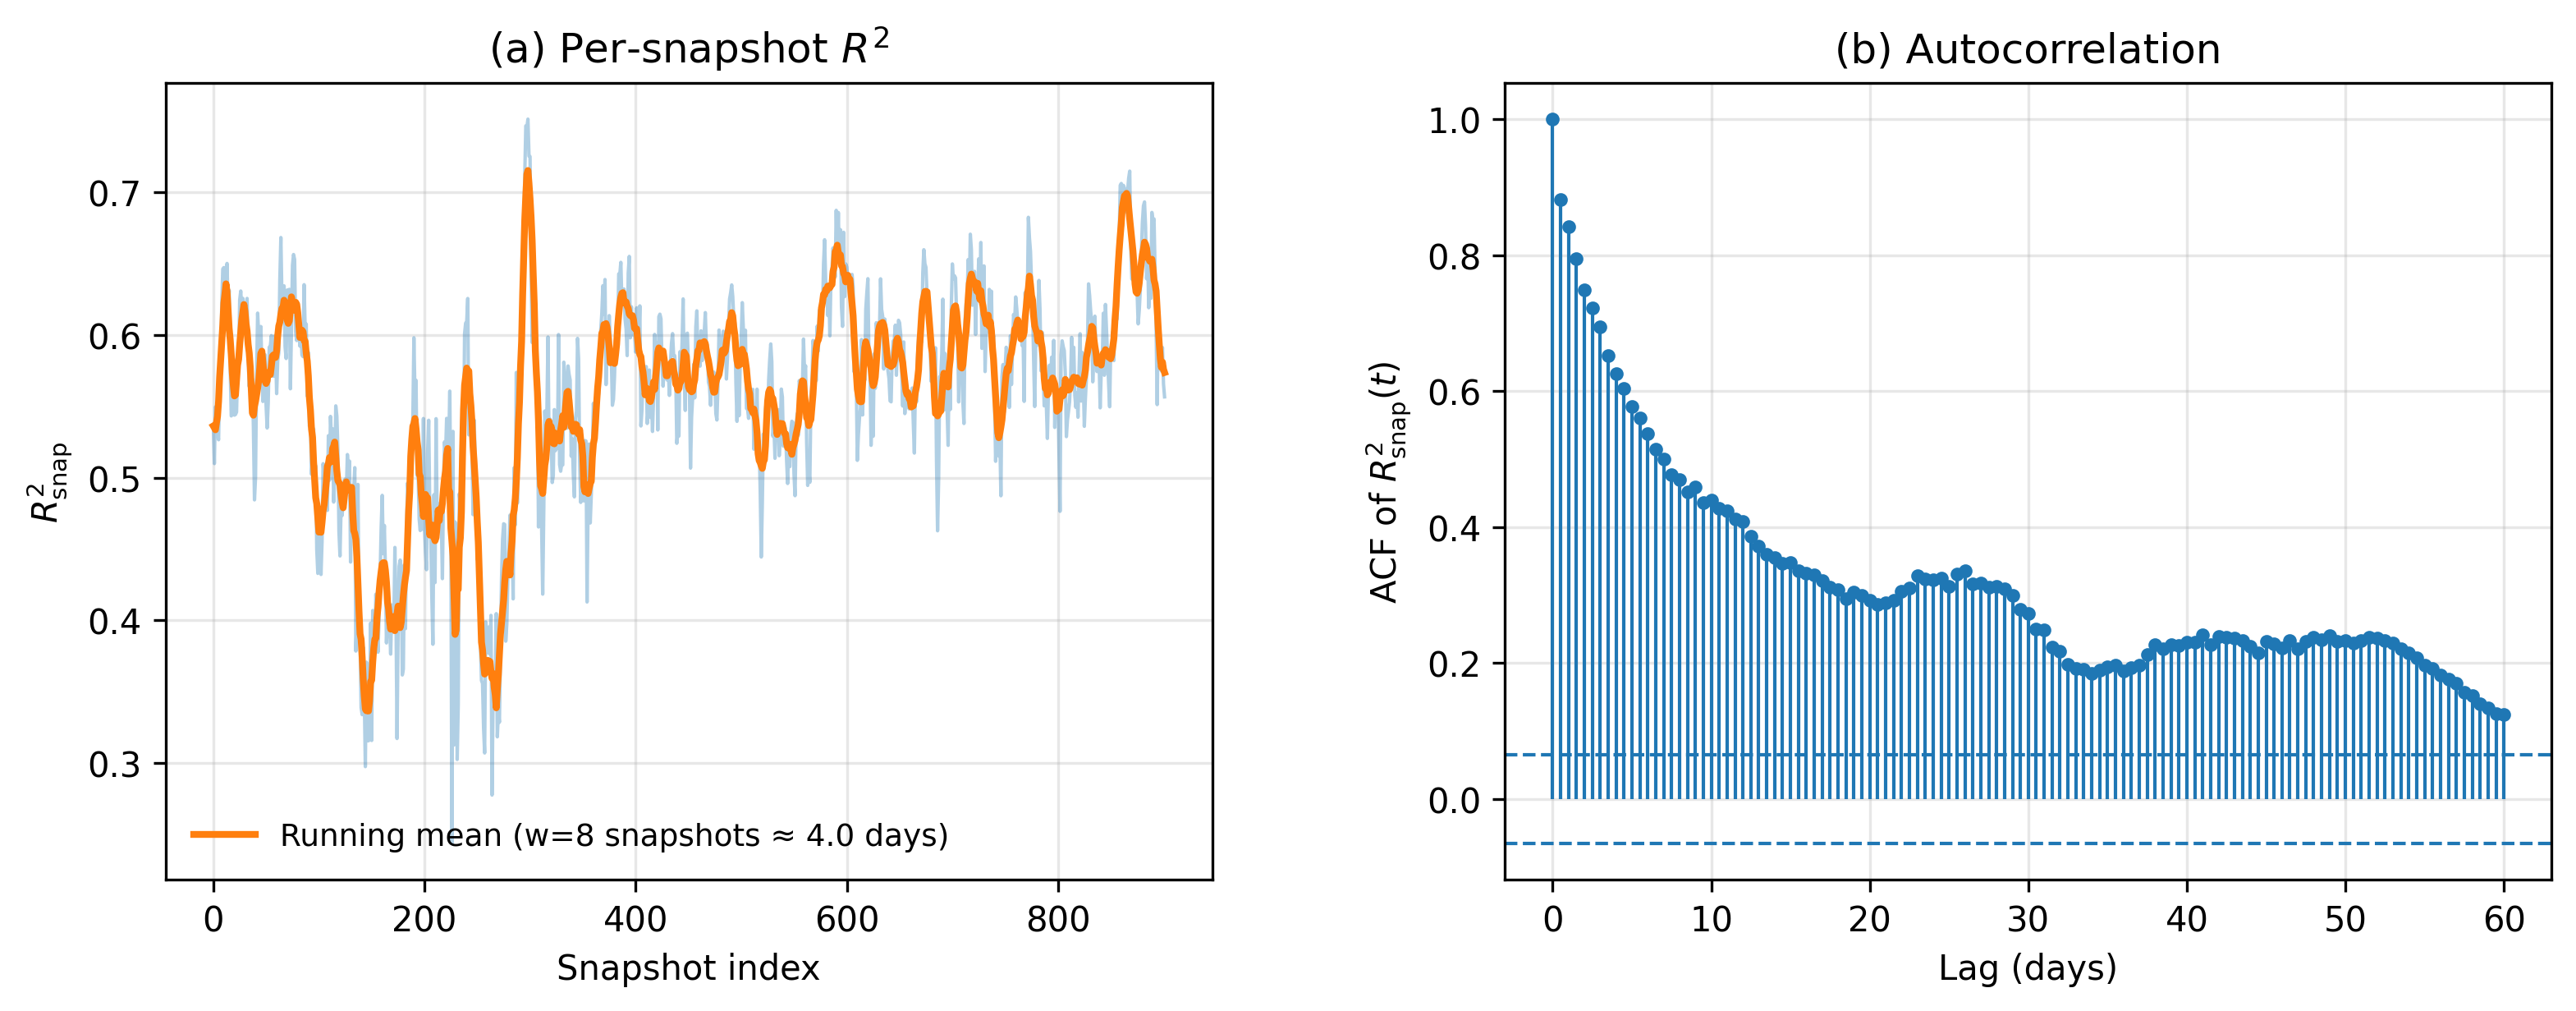

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def _running_mean_nan(y, window: int):
    """NaN-safe running mean using convolution."""
    y = np.asarray(y, dtype=float)
    if window <= 1:
        return y
    m = np.isfinite(y)
    y0 = np.where(m, y, 0.0)
    w0 = np.where(m, 1.0, 0.0)
    k = np.ones(window, dtype=float)
    num = np.convolve(y0, k, mode="same")
    den = np.convolve(w0, k, mode="same")
    return num / np.maximum(den, 1e-12)

def acf(x, max_lag=120):
    """NaN-safe autocorrelation."""
    x = np.asarray(x, dtype=float)
    m = np.isfinite(x)
    x = x[m]
    x = x - x.mean()
    denom = np.sum(x**2) + 1e-12
    out = np.empty(max_lag + 1, dtype=float)
    out[0] = 1.0
    for k in range(1, max_lag + 1):
        out[k] = np.sum(x[:-k] * x[k:]) / denom
    return out

def plot_r2_timeseries_and_acf(
    r2,
    x=None,
    dt_hours=12,              # set to 12 for your case
    smooth_window=8,          # 8 snapshots ~ 4 days
    max_lag=120,
    savepath=None,
    dpi=300
):
    r2 = np.asarray(r2, dtype=float)
    if x is None:
        x = np.arange(len(r2))
        xlabel_ts = "Snapshot index"
    else:
        x = np.asarray(x, dtype=float)
        xlabel_ts = "Time"

    # ACF + CI
    rho = acf(r2, max_lag=max_lag)
    N = np.isfinite(r2).sum()
    ci = 1.96 / np.sqrt(N)

    # lag axis in days (optional)
    dt_days = dt_hours / 24.0
    lag_days = np.arange(max_lag + 1) * dt_days

    # --- 1 row, 2 columns: time series left, ACF right ---
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), dpi=dpi)
    plt.subplots_adjust(wspace=0.28)

    # (a) Time series
    ax = axes[0]
    ax.plot(x, r2, alpha=0.35, linewidth=1)
    if smooth_window and smooth_window > 1:
        r2_smooth = _running_mean_nan(r2, smooth_window)
        ax.plot(x, r2_smooth, linewidth=2,
                label=f"Running mean (w={smooth_window} snapshots ≈ {smooth_window*dt_days:.1f} days)")
        ax.legend(frameon=False, fontsize=9)
    ax.set_xlabel(xlabel_ts)
    ax.set_ylabel(r"$R^2_{\mathrm{snap}}$")
    ax.set_title("(a) Per-snapshot $R^2$")
    ax.grid(True, alpha=0.3)

    # (b) ACF
    ax = axes[1]
    markerline, stemlines, baseline = ax.stem(lag_days, rho, basefmt=" ")
    plt.setp(markerline, markersize=3)
    plt.setp(stemlines, linewidth=1)

    ax.axhline(ci,  ls="--", linewidth=1)
    ax.axhline(-ci, ls="--", linewidth=1)
    ax.set_xlabel("Lag (days)")
    ax.set_ylabel(r"ACF of $R^2_{\mathrm{snap}}(t)$")
    ax.set_title("(b) Autocorrelation")
    ax.grid(True, alpha=0.3)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")
    plt.show()

# ------------------- Example usage -------------------
r2 = load_r2_list("../../../outputs/cfg_19/test_stats.json", key="image_r2_list")
plot_r2_timeseries_and_acf(
    r2,
    dt_hours=12,
    smooth_window=8,
    max_lag=120,
    savepath="r2_timeseries_acf.png"
)

# plot snapshots of the lowest R2 case

In [1]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_19/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_19/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)

# read the norm from pt file
ckpt_path = "../../../check_point/cfg_19/best_unet_conv.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
norm = ckpt["norm"]   # dict with X_mu, X_sd, y_mu, y_sd

y_mu = norm["y_mu"]   # scalar
y_sd = norm["y_sd"]   # scalar

y_true_phys = y_true * y_sd + y_mu
y_pred_phys = y_pred * y_sd + y_mu

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
import cmocean.cm as cmo

def _r2_one_map(true_map, pred_map, eps=1e-12):
    yt = np.asarray(true_map, dtype=np.float64).ravel()
    yp = np.asarray(pred_map, dtype=np.float64).ravel()
    m = np.isfinite(yt) & np.isfinite(yp)
    yt = yt[m]; yp = yp[m]
    if yt.size < 2:
        return np.nan
    sse = np.sum((yp - yt) ** 2)
    sst = np.sum((yt - yt.mean()) ** 2)
    return 1.0 - sse / (sst + eps)

def plot_snapshot_true_pred_error_paper(
    y_true_phys,
    y_pred_phys,
    XC_c,
    YC_c,
    t=5,
    units=r"W m$^{-2}$",
    figsize=(13.2, 4.2),
    dpi=300,
    main_cmap=cmo.balance,
    err_cmap=cmo.balance,
    main_q=99,
    err_q=99,
    savepath=None,
    print_r2=True,
    show_r2_in_title=True,
    # --- NEW: highlight a y-strip ---
    highlight_strip=True,
    strip_rows=10,              # first 10 y grid points (j=0..9)
    strip_from="top",           # "top" -> j=0..9; "bottom" -> last 10 rows
    strip_edgecolor="red",
    strip_linewidth=2.2,
):
    """
    Paper-style plot for a signed variable:
    truth, prediction, and error = prediction - truth.
    Optionally draws a red rectangle highlighting a meridional strip
    (first/last `strip_rows` y-grid points) on all panels.
    """

    true_map = y_true_phys[t, 0] if y_true_phys.ndim == 4 else y_true_phys[t]
    pred_map = y_pred_phys[t, 0] if y_pred_phys.ndim == 4 else y_pred_phys[t]
    err_map  = pred_map - true_map

    true_map = np.asarray(true_map, dtype=float)
    pred_map = np.asarray(pred_map, dtype=float)
    err_map  = np.asarray(err_map, dtype=float)

    r2 = _r2_one_map(true_map, pred_map)
    if print_r2:
        print(f"Snapshot t={t}: R2 (map-wise) = {r2:.4f}")

    # coordinates (km)
    x = np.asarray(XC_c, dtype=float) / 1000.0
    y = np.asarray(YC_c, dtype=float) / 1000.0

    # shared symmetric color scale for signed truth/prediction
    main_pool = np.concatenate([
        true_map[np.isfinite(true_map)].ravel(),
        pred_map[np.isfinite(pred_map)].ravel()
    ])
    vabs_main = np.nanpercentile(np.abs(main_pool), main_q)
    norm_main = TwoSlopeNorm(vmin=-vabs_main, vcenter=0.0, vmax=vabs_main)

    # symmetric color scale for signed error
    vabs_err = np.nanpercentile(np.abs(err_map[np.isfinite(err_map)]), err_q)
    norm_err = TwoSlopeNorm(vmin=-vabs_err, vcenter=0.0, vmax=vabs_err)

    fig, axes = plt.subplots(1, 3, figsize=figsize, dpi=dpi)
    plt.subplots_adjust(left=0.06, right=0.94, bottom=0.14, top=0.86, wspace=0.18)

    panels = [
        (true_map, "Truth", norm_main, main_cmap),
        (pred_map, "Prediction", norm_main, main_cmap),
        (err_map,  "Error (Prediction - Truth)", norm_err, err_cmap),
    ]

    # --- NEW: compute rectangle bounds for the strip using YC_c ---
    rect = None
    if highlight_strip:
        H = true_map.shape[0]
        if strip_rows <= 0 or strip_rows > H:
            raise ValueError(f"strip_rows must be in [1, {H}] but got {strip_rows}")

        # pick strip row indices
        if strip_from.lower() == "top":
            j0, j1 = 0, strip_rows
        elif strip_from.lower() == "bottom":
            j0, j1 = H - strip_rows, H
        else:
            raise ValueError("strip_from must be 'top' or 'bottom'")

        # rectangle bounds in physical coords:
        # use min/max of x for horizontal extent
        xmin = float(np.nanmin(x))
        xmax = float(np.nanmax(x))

        # y extent from the selected rows
        y_strip = y[j0:j1, :]
        ymin = float(np.nanmin(y_strip))
        ymax = float(np.nanmax(y_strip))

        rect = (xmin, ymin, xmax - xmin, ymax - ymin)  # (x0, y0, w, h)

    ims = []
    for i, (ax, (field, ttl, norm, cmap)) in enumerate(zip(axes, panels)):
        im = ax.pcolormesh(
            x, y, field,
            shading="auto",
            cmap=cmap,
            norm=norm,
            rasterized=True,
        )
        ims.append(im)

        ax.set_title(ttl, fontsize=12)
        ax.set_aspect("equal")
        ax.set_xlabel("X (km)", fontsize=10)
        ax.tick_params(axis="both", labelsize=9)
        ax.set_ylabel("Y (km)" if i == 0 else "", fontsize=10)

        ax.text(
            0.02, 0.98, f"({chr(97+i)})",
            transform=ax.transAxes,
            ha="left", va="top",
            fontsize=11,
            fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.75, pad=1.2),
        )

        # --- NEW: draw strip rectangle on each panel ---
        if rect is not None:
            x0, y0, w, h = rect
            ax.add_patch(
                Rectangle(
                    (x0, y0), w, h,
                    fill=False,
                    edgecolor=strip_edgecolor,
                    linewidth=strip_linewidth,
                    zorder=10,
                )
            )

    if show_r2_in_title:
        fig.suptitle(f"Test snapshot {t}  |  $R^2_{{\\mathrm{{snap}}}}$ = {r2:.3f}", fontsize=13)

    cbar_main = fig.colorbar(ims[0], ax=axes[:2], fraction=0.035, pad=0.02)
    cbar_main.set_label(units, fontsize=10)
    cbar_main.ax.tick_params(labelsize=9)

    cbar_err = fig.colorbar(ims[2], ax=axes[2], fraction=0.046, pad=0.02)
    cbar_err.set_label(units, fontsize=10)
    cbar_err.ax.tick_params(labelsize=9)

    if savepath is not None:
        fig.savefig(savepath, dpi=dpi, bbox_inches="tight")

    plt.show()
    return r2

Snapshot t=298: R2 (map-wise) = 0.6951


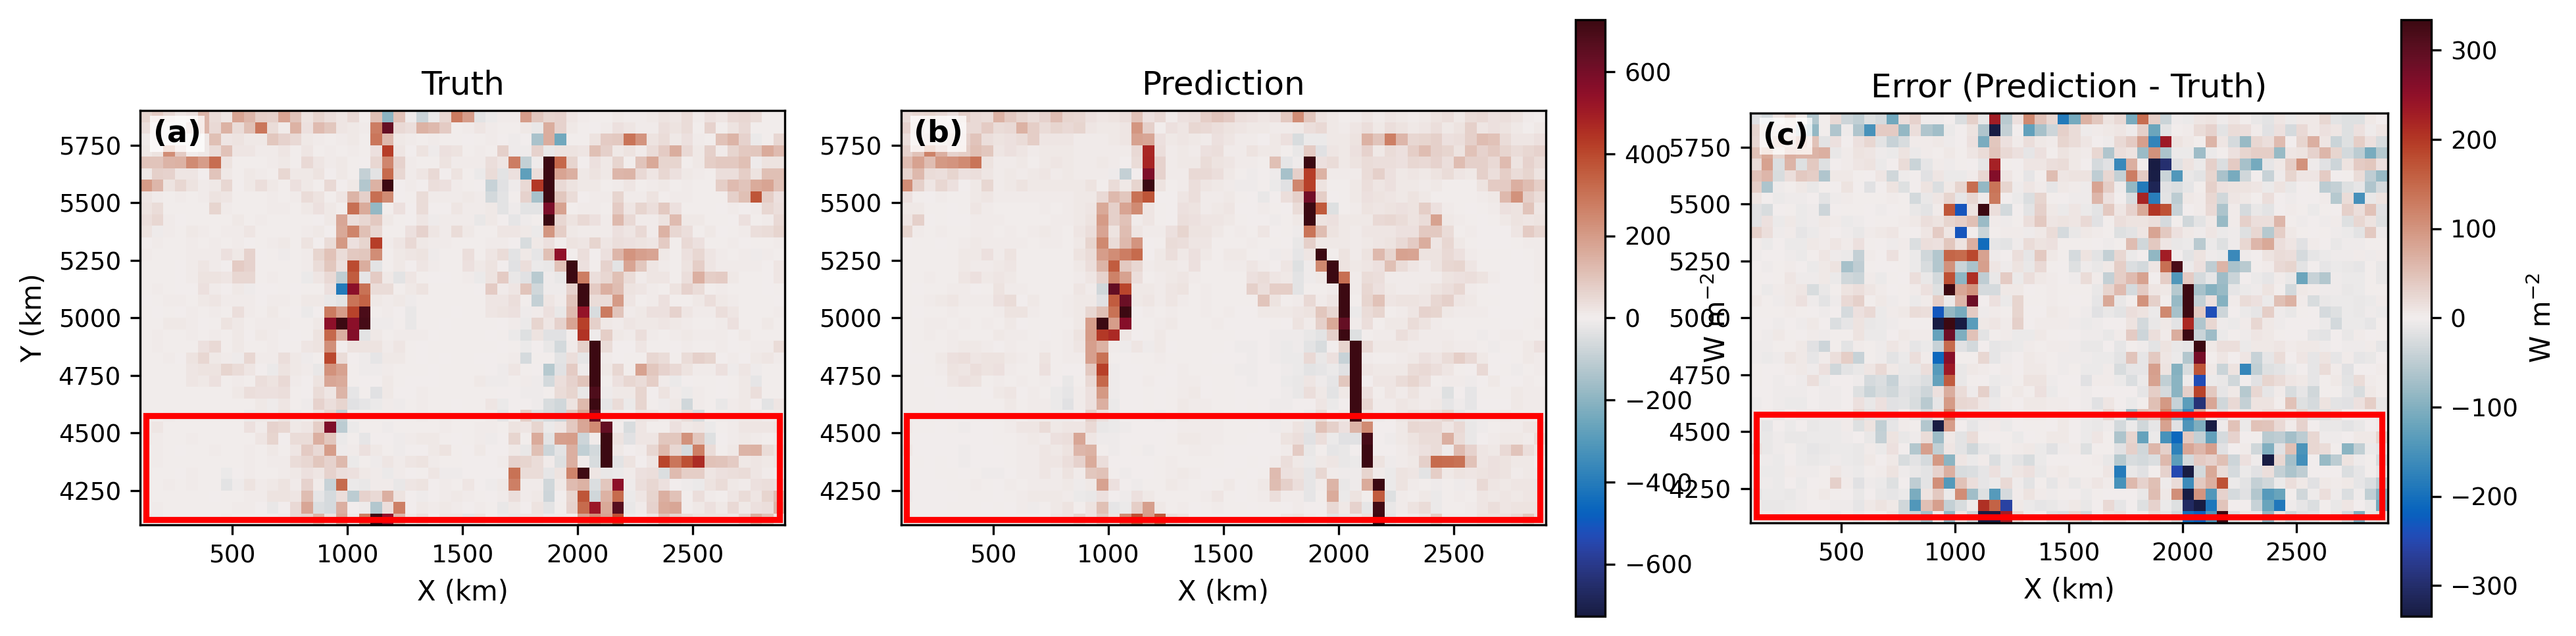

0.6950764776198955

In [5]:
plot_snapshot_true_pred_error_paper(
    y_true_phys=y_true_phys[:,:,20:,:],
    y_pred_phys=y_pred_phys[:,:,20:,:],
    XC_c=XC_c[82:118,2:58],
    YC_c=YC_c[82:118,2:58],
    t=298,
    units=r"W m$^{-2}$",   # change if needed
    # savepath="./snapshot_true_pred_error_t226.png",
    show_r2_in_title = False,
)

# R2 autocorrelation function

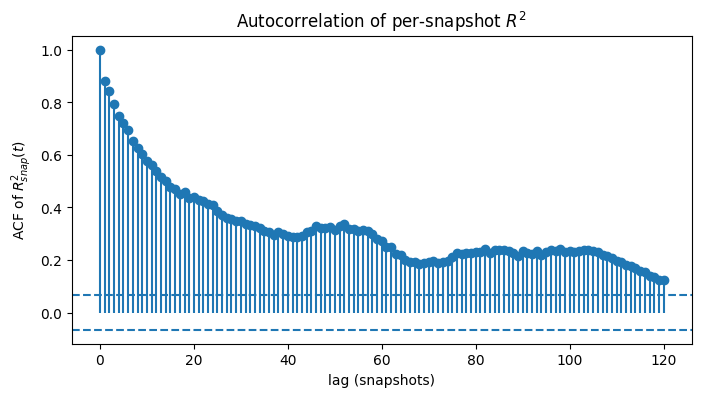

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def acf(x, max_lag=100):
    x = np.asarray(x, dtype=float)
    m = np.isfinite(x)
    x = x[m]
    x = x - x.mean()
    n = len(x)
    denom = np.sum(x**2)
    out = np.empty(max_lag+1)
    out[0] = 1.0
    for k in range(1, max_lag+1):
        out[k] = np.sum(x[:-k]*x[k:]) / (denom + 1e-12)
    return out

r2 = np.asarray(r2_snap, float)          # length N=903
max_lag = 120
rho = acf(r2, max_lag=max_lag)

# 95% CI for white noise approx ±1.96/sqrt(N)
ci = 1.96 / np.sqrt(np.isfinite(r2).sum())

plt.figure(figsize=(8,4))
plt.stem(range(max_lag+1), rho, basefmt=" ")
plt.axhline(ci,  ls="--")
plt.axhline(-ci, ls="--")
plt.xlabel("lag (snapshots)")
plt.ylabel("ACF of $R^2_{snap}(t)$")
plt.title("Autocorrelation of per-snapshot $R^2$")
plt.show()

In [22]:
import numpy as np

def ar1_phi(x):
    x = np.asarray(x, float)
    m = np.isfinite(x)
    x = x[m]
    x = x - x.mean()
    if len(x) < 3:
        return np.nan
    return np.corrcoef(x[:-1], x[1:])[0,1]
r2_snap = load_r2_list("../../../outputs/cfg_19/test_stats.json", key="image_r2_list")
phi = ar1_phi(r2_snap)
print("AR(1) phi ~", phi)

# correlation time in snapshot units (roughly)
tau = -1.0 / np.log(np.clip(phi, 1e-6, 0.999999))
print("Approx correlation time (snapshots):", tau)

AR(1) phi ~ 0.881384838591016
Approx correlation time (snapshots): 7.920106512905635


In [38]:
import numpy as np

def runs_test_above_median(x):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    med = np.median(x)
    b = (x >= med).astype(int)

    # count runs
    runs = 1 + np.sum(b[1:] != b[:-1])
    n1 = np.sum(b==1); n0 = np.sum(b==0)
    n = n0 + n1
    if n0 == 0 or n1 == 0:
        return np.nan, np.nan

    # expected runs and variance under randomness
    mu = 1 + 2*n0*n1/n
    var = (2*n0*n1*(2*n0*n1 - n)) / (n**2 * (n-1) + 1e-12)
    z = (runs - mu) / np.sqrt(var + 1e-12)
    return runs, z

runs, z = runs_test_above_median(r2_snap)
print("runs:", runs, " z-score:", z, " (|z|>~2 suggests non-random clustering)")

runs: 157  z-score: -19.655761943529008  (|z|>~2 suggests non-random clustering)


# submesoscale field autocorrelation

In [29]:
# compare the npz data with data after data_loader
import torch
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid

from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
import importlib
from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
XC_c = ds_coarse["XC"]
YC_c = ds_coarse["YC"]

y_true_path = "../../../outputs/cfg_9/test_y_true.npy"
y_pred_path = "../../../outputs/cfg_9/test_y_pred.npy"
y_true = np.load(y_true_path)   # shape (N,1,H,W)
y_pred = np.load(y_pred_path)   # shape (N,1,H,W)

# read the norm from pt file
ckpt_path = "../../../check_point/cfg_9/best_unet_conv.pt"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
norm = ckpt["norm"]   # dict with X_mu, X_sd, y_mu, y_sd

y_mu = norm["y_mu"]   # scalar
y_sd = norm["y_sd"]   # scalar

y_true_phys = y_true * y_sd + y_mu
y_pred_phys = y_pred * y_sd + y_mu

RMS activity correlation time (e-fold): 40.00 days
RMS activity correlation time (integral): 61.11 days


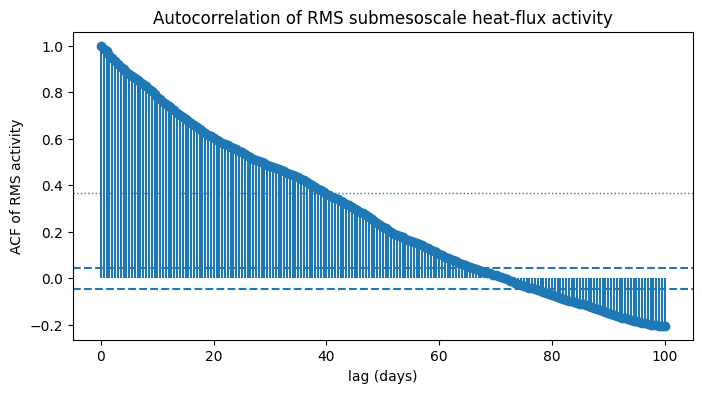

In [30]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Option B: RMS flux activity index s(t) = sqrt(mean(y^2))
# Then compute ACF and an e-folding correlation time.
# Assumes 12-hour snapshots => dt_days = 0.5
# -----------------------------

def rms_activity(y_maps):
    """
    y_maps: (N,H,W) or (N,1,H,W)
    returns s: (N,) where s[t] = sqrt(mean(y[t]^2)) over domain
    """
    Y = np.asarray(y_maps, dtype=np.float64)
    if Y.ndim == 4 and Y.shape[1] == 1:
        Y = Y[:, 0]
    # RMS over spatial domain per snapshot
    s = np.sqrt(np.nanmean(Y**2, axis=(1, 2)))
    return s

def acf_1d(x, max_lag=200):
    """
    Autocorrelation function for a 1D series x, NaN-safe.
    Returns ACF[0..max_lag] with ACF[0]=1.
    """
    x = np.asarray(x, dtype=np.float64)
    m = np.isfinite(x)
    x = x[m]
    x = x - x.mean()
    denom = np.sum(x**2) + 1e-12

    out = np.empty(max_lag + 1, dtype=np.float64)
    out[0] = 1.0
    for k in range(1, max_lag + 1):
        out[k] = np.sum(x[:-k] * x[k:]) / denom
    return out

def corr_time_efold(acf_vals, dt_days=0.5):
    """
    E-folding correlation time: first lag where ACF <= 1/e.
    Returns tau in days.
    """
    target = 1.0 / np.e
    idx = np.where(acf_vals <= target)[0]
    if len(idx) == 0:
        return np.nan
    return float(idx[0] * dt_days)

def corr_time_integral(acf_vals, dt_days=0.5):
    """
    Integral time scale: tau = dt * (1 + 2 * sum_{k>=1} ACF[k]) 
    summed until ACF first becomes negative (common practice).
    Returns tau in days.
    """
    acf_vals = np.asarray(acf_vals, dtype=np.float64)
    # stop at first negative lag (exclude it)
    neg = np.where(acf_vals[1:] < 0)[0]
    kmax = (neg[0] + 1) if len(neg) > 0 else (len(acf_vals) - 1)
    tau = dt_days * (1.0 + 2.0 * np.sum(acf_vals[1:kmax+1]))
    return float(tau)

# -----------------------------
# USAGE
# -----------------------------
# y_true_test should be time-ordered test targets in physical units:
# shape (N,H,W) or (N,1,H,W)
dt_days = 0.5   # 12 hours
max_lag = 200   # adjust as needed (in snapshots)

s = rms_activity(y_true_phys)
acf_s = acf_1d(s, max_lag=max_lag)

tau_efold_days = corr_time_efold(acf_s, dt_days=dt_days)
tau_int_days   = corr_time_integral(acf_s, dt_days=dt_days)

print(f"RMS activity correlation time (e-fold): {tau_efold_days:.2f} days")
print(f"RMS activity correlation time (integral): {tau_int_days:.2f} days")

# Optional plot
ci = 1.96 / np.sqrt(np.isfinite(s).sum())  # white-noise 95% approx
lags_days = np.arange(max_lag + 1) * dt_days

plt.figure(figsize=(8,4))
plt.stem(lags_days, acf_s, basefmt=" ")
plt.axhline(ci,  ls="--")
plt.axhline(-ci, ls="--")
plt.axhline(1/np.e, ls=":", linewidth=1)
plt.xlabel("lag (days)")
plt.ylabel("ACF of RMS activity")
plt.title("Autocorrelation of RMS submesoscale heat-flux activity")
plt.show()

In [32]:
def running_mean_nan(x, w):
    x = np.asarray(x, float)
    m = np.isfinite(x)
    x0 = np.where(m, x, 0.0)
    w0 = np.where(m, 1.0, 0.0)
    k = np.ones(w)
    num = np.convolve(x0, k, mode="same")
    den = np.convolve(w0, k, mode="same")
    return num / np.maximum(den, 1e-12)

dt_days = 0.5
w_days = 90
w = int(w_days / dt_days)   # 30 days / 0.5 = 60 snapshots

s = rms_activity(y_true_phys)
s_hp = s - running_mean_nan(s, w)

acf_hp = acf_1d(s_hp, max_lag=400)
tau_hp = corr_time_efold(acf_hp, dt_days=dt_days)
print("High-pass (30d) RMS tau (e-fold):", tau_hp, "days")

High-pass (30d) RMS tau (e-fold): 10.0 days
